In [3]:
import pandas as pd

In [4]:
import platform
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')


# OS에 따라서 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    # 리눅스용 폰트 로드
    plt.rc('font', family='NanumGothicCoding')
    print("(리눅스) 한글폰트 로드 완료")

elif os_name == 'Windows':
    # 윈도우용 폰트 로드
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")

elif os_name == 'Darwin':
    # 맥용 폰트 로드
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")

else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(윈도우) 한글폰트 로드 완료


In [5]:
df = pd.read_csv('./AICE Associate 샘플문항_회귀/signal_data.csv')
df.head(4)

,RID,Time_Departure,Time_Arrival,Distance,Time_Driving,Speed_Per_Hour,Address1,Address2,Weekday,Hour,Day,Signaltype
0,router-84875df7fc-cmkz9-2-9617301-0,19:43:56,19:56:38.537000,3246.0,762.653992,15.322283,경기도,평택시,0,19,27,11.0
1,router-84875df7fc-scxcj-6-13366366-0,12:23:05,12:36:32.620000,3858.0,796.081970,17.446445,경기도,의정부시,4,12,24,17.0
2,router-84875df7fc-52vz8-6-62202063-0,19:10:35,19:29:07.306000,4125.0,1112.468018,13.348698,경기도,광명시,0,19,27,24.0
3,router-84875df7fc-8n4sw-5-6914479-0,11:59:58,12:10:55.999000,3748.0,651.973022,20.695335,경기도,안산시 상록구,0,11,20,19.0


<Axes: xlabel='Address1', ylabel='count'>

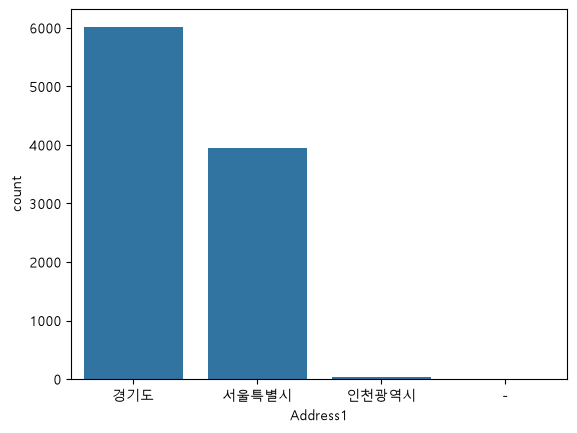

In [6]:
sns.countplot(data=df, x='Address1')


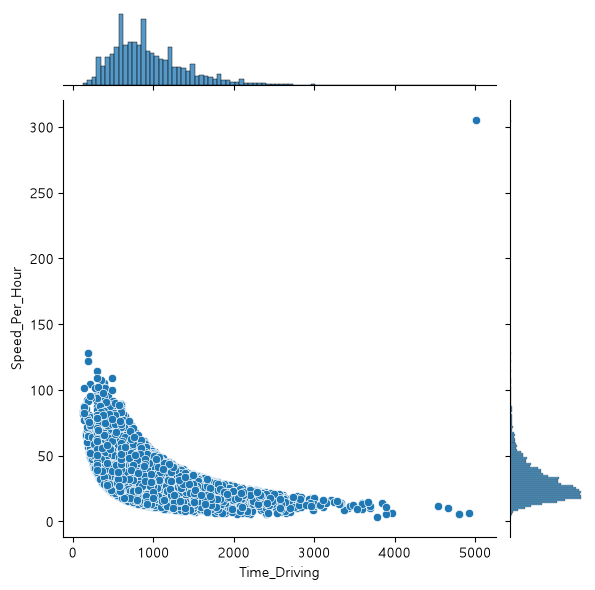

In [7]:
sns.jointplot(data=df, x='Time_Driving', y='Speed_Per_Hour')

In [8]:
df_temp = df.drop(df[df['Speed_Per_Hour'] >= 300].index, axis=0)
df_temp = df_temp.drop(columns=["RID"])


In [9]:
print('결측치 제거 전\n', df_temp.isnull().sum())

결측치 제거 전
 Time_Departure    0
Time_Arrival      0
Distance          2
Time_Driving      0
Speed_Per_Hour    0
Address1          0
Address2          0
Weekday           0
Hour              0
Day               0
Signaltype        0
dtype: int64


In [10]:
df_na = df_temp.dropna()
print('결측치 제거 후\n',df_na.isnull().sum())

결측치 제거 후
 Time_Departure    0
Time_Arrival      0
Distance          0
Time_Driving      0
Speed_Per_Hour    0
Address1          0
Address2          0
Weekday           0
Hour              0
Day               0
Signaltype        0
dtype: int64


In [11]:
df_na = df_na.drop(columns=['Time_Departure', 'Time_Arrival'])
df_preset = pd.get_dummies(data=df_na, columns=['Address1','Address2'])
df_preset.info()

<class 'pandas.DataFrame'>
Index: 9997 entries, 0 to 9999
Data columns (total 82 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Distance           9997 non-null   float64
 1   Time_Driving       9997 non-null   float64
 2   Speed_Per_Hour     9997 non-null   float64
 3   Weekday            9997 non-null   int64  
 4   Hour               9997 non-null   int64  
 5   Day                9997 non-null   int64  
 6   Signaltype         9997 non-null   float64
 7   Address1_-         9997 non-null   bool   
 8   Address1_경기도       9997 non-null   bool   
 9   Address1_서울특별시     9997 non-null   bool   
 10  Address1_인천광역시     9997 non-null   bool   
 11  Address2_가평군       9997 non-null   bool   
 12  Address2_강남구       9997 non-null   bool   
 13  Address2_강동구       9997 non-null   bool   
 14  Address2_강북구       9997 non-null   bool   
 15  Address2_강서구       9997 non-null   bool   
 16  Address2_계양구       9997 non-null   bool 

In [12]:
from sklearn.model_selection import train_test_split

X = df_preset.drop('Time_Driving', axis=1)
y = df_preset['Time_Driving']

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.2,random_state=42)

In [13]:
from sklearn.preprocessing import RobustScaler

rs = RobustScaler()

X_train = rs.fit_transform(X_train)
X_valid = rs.transform(X_valid)

print(round(np.max(X_valid)))

6


In [14]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=120,max_depth=5,min_samples_split=3)
dt.fit(X_train, y_train)



UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

DecisionTreeRegressor(max_depth=5, min_samples_split=3, random_state=120)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=120, max_depth=5, min_samples_split=3)
rf.fit(X_train, y_train)

In [ ]:
fi = pd.DataFrame({
    'feature' : X.columns,
    'importance' : rf.feature_importances_,
})

fi =fi.sort_values(['importance'],ascending=False)[:10]

sns.barplot(data=fi, x='importance', y='feature', palette='viridis')


In [ ]:
y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

from sklearn.metrics import mean_absolute_error

dt_mae = mean_absolute_error(y_valid, y_pred_dt)
rf_mae = mean_absolute_error(y_valid, y_pred_rf)

print(dt_mae)
print(rf_mae)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

In [ ]:
model=Sequential([
    Dense(64,activation='selu', input_dim = X_train.shape[1]),
    Dropout(0.1),
    Dense(32, activation='selu'),
    Dense(16, activation='selu'),
    Dense(1, activation='linear'),
])

estop = EarlyStopping(monitor='val_loss', patience=9)
model.compile(
    optimizer = 'adam',
    metrics = ['mse'],
    loss = 'mean_squared_error'
)

history = model.fit(X_train, y_train,
                    epochs=30,
                    batch_size=128,
                    validation_data=(X_valid, y_valid),
                    callbacks=[estop])


In [ ]:
plt.plot(history.history['mse'])
plt.plot(history.history['val_mse'])
plt.title('Model MSE')
plt.legend(['mse','val_mse'])
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.show()